
<div dir=ltr align=center>

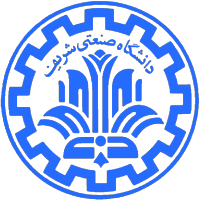

<font color=0F5298 size=7>
Machine Learning <br>
<font color=2565AE size=5>
Computer Engineering Department <br>
Fall 2025 <br>
<font color=3C99D size=5>
    Clustering: Gaussian Mixture Model <br>
<font color=696880 size=4>
    Prepared by Benyamin Ghanbari <br>

<font color=696880 size=2>
    Curated by Alireza Mirshafieian

____

# Student Information

In [1]:
student_number = '402106112'
full_name = 'Amir Mohammad Sharbati'

# Customer Segmentation Using GMM 

## Description:
In this project, you will implement a Gaussian Mixture Model (GMM) from scratch and use it to perform customer segmentation based on demographic and behavioral data. Customer segmentation is the process of grouping customers into clusters such that customers within the same cluster are more similar to each other than to those in other clusters. In this assignment, segmentation is done using a probabilistic clustering approach, where each customer is assigned a probability of belonging to each cluster based on features such as Age, Annual Income, and Spending Score. 

**⚠️ Notice:** You are allowed to use only the imported libraries and must follow the provided function structure.

# 📝 **Project Instructions**

1. **Load the customer dataset**  
   Load the dataset containing customer information such as **Age, Annual Income, Spending Score**, and optionally **Gender**.

2. **Feature selection**  
    Anything that you need.

3. **Standardize features**  
   Normalize the numerical features using **standardization** so that each feature has **mean 0 and standard deviation 1**.

4. **Initialize GMM parameters**  
   Randomly initialize **cluster weights, means, and covariance matrices** for a chosen number of clusters **K**.

5. **Expectation-Maximization (EM) steps**  
   - **Expectation step:** Compute the **responsibility** of each cluster for every customer.  
   - **Maximization step:** Update **weights, means, and covariances** based on responsibilities.  
   - Repeat until **log-likelihood converges** or **max iterations** is reached.

6. **Multiple initializations**  
   Run the GMM algorithm **multiple times** with different random seeds and select the model with the **highest log-likelihood** to avoid poor local minima.

7. **Select the optimal number of clusters**  
   Compute **BIC (Bayesian Information Criterion)** for different values of **K** and choose the one with the **lowest BIC**.

8. **Assign clusters to customers**  
   For the final model, assign each customer to the cluster with the **highest responsibility**.

9. **Visualize clusters**  
   - **2D scatter plots:** Plot feature pairs (e.g., Age vs Income, Age vs Spending Score) with points colored by cluster.  
   - **Cluster centroids and circles:** Highlight **cluster centers** and **spread** using semi-transparent colored circles.  
   - **3D scatter plot:** Visualize clusters in 3D with **centroids marked**.



# 📤 **Expected Output**

- A **clustered customer dataset** showing each customer assigned to a **GMM cluster**  
- **2D scatter plots** of feature pairs (e.g., Age vs Income, Age vs Spending Score, Income vs Spending Score) with:  
  - Cluster points colored by cluster  
  - **Centroids** marked  
  - **Semi-transparent circles** showing cluster spread  
- A **3D scatter plot** visualizing all three features with cluster centroids highlighted  
- A **BIC vs. K plot** showing the Bayesian Information Criterion for different numbers of clusters, helping identify the **optimal K**  
- **Observe** which features distinguish clusters and how changing **K** affects segmentation quality


In [95]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.patches import Circle

In [96]:
# read data 
df = pd.read_csv('Mall_Customers.csv')
df.head(10)

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
5,6,Female,22,17,76
6,7,Female,35,18,6
7,8,Female,23,18,94
8,9,Male,64,19,3
9,10,Female,30,19,72


In [97]:
# data prepration (feature selection and scaling)

X = df[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']].values

def standard_scale(X):
    means = X.mean(axis=0)
    stds = X.std(axis=0)
    X_scaled = (X - means) / stds
    return X_scaled, means, stds

X_scaled, means_X, stds_X = standard_scale(X)

In [98]:
# GMM from scratch
def initialize_parameters(X, k, rng):
    n, d = X.shape

    # Initialize weights equally
    weights = np.ones(k) / k

    # Choose k random points as initial means
    indices = rng.choice(n, size=k, replace=False)
    means = X[indices]

    # Initialize covariance matrices as identity matrices
    covs = np.array([np.eye(d) for _ in range(k)])

    return weights, means, covs


def gaussian_pdf_all(X, mean, cov):
    d = X.shape[1]
    diff = X - mean

    cov_determinant = np.linalg.det(cov)
    cov_inverse = np.linalg.inv(cov)

    # normalization constant (for log N(x|mean, cov))
    norm_const = -0.5 * (d * np.log(2 * np.pi) + np.log(cov_determinant))

    # exponent term
    exponent = -0.5 * np.sum(diff @ cov_inverse * diff, axis=1)

    return np.exp(norm_const + exponent)


def expectation_step(X, weights, means, covs):
    n, d = X.shape
    k = len(weights)

    resp = np.zeros((n, k)) # responsibility matrix: (n_samples, k)

    # compute weighted PDF for each component
    for i in range(k):
        resp[:, i] = weights[i] * gaussian_pdf_all(X, means[i], covs[i])

    # normalize responsibilities across clusters
    resp_sum = resp.sum(axis=1, keepdims=True)
    resp /= (resp_sum + 1e-12)

    return resp


def maximization_step(X, resp):
    n, d = X.shape
    k = resp.shape[1]

    # new parameter values
    weights = np.zeros(k)
    means = np.zeros((k, d))
    covs = np.zeros((k, d, d))

    Nk = resp.sum(axis=0)  # cluster sizes

    for i in range(k):
        weights[i] = Nk[i] / n
        means[i] = (resp[:, i][:, None] * X).sum(axis=0) / Nk[i]

        diff = X - means[i]
        covs[i] = (resp[:, i][:, None] * diff).T @ diff / Nk[i]

        # Regularization (important to avoid singular matrices)
        covs[i] += 1e-6 * np.eye(d)

    return weights, means, covs


def compute_log_likelihood(X, weights, means, covs):
    n, d = X.shape
    k = len(weights)

    pdf_sum = np.zeros(n)

    for i in range(k):
        pdf_sum += weights[i] * gaussian_pdf_all(X, means[i], covs[i])

    # log-likelihood
    ll = np.sum(np.log(pdf_sum + 1e-12))
    return ll


def gmm_train(X, k, max_iter=200, tol=1e-4, seed=None):
    rng = np.random.default_rng(seed) # rng = random number generator
    weights, means, covs = initialize_parameters(X, k, rng)
    prev_ll = None

    for _ in range(max_iter):
        resp = expectation_step(X, weights, means, covs)  # E-step
        weights, means, covs = maximization_step(X, resp) # # M-step

        ll = compute_log_likelihood(X, weights, means, covs)

        # Check convergence
        if prev_ll is not None and abs(ll - prev_ll) < tol:
            break

        prev_ll = ll

    return weights, means, covs, resp, ll

In [99]:
# compute best k using BIC: BIC = −2⋅log-likelihood + params_count⋅log(n)
# means : k*d (each mean has d elemenents)
# covariances : k*d*(d+1)/2 (Because covariance is symmetric, so we don't need d^2 elements)
# mixture weights : k-1 (Because sum of them is 1, we can skip last one :))

def compute_bic(ll, k, n, d):
    num_params = (k * d) + (k * d * (d+1)//2) + (k-1)
    return -2*ll + num_params * np.log(n)

######### NOTE : I check several random initializations #########
seeds = [0, 7, 11, 42, 111, 512, 1404, 2025] # We should check the model for different random initialization

bic_values = []
k_range = range(2,9)
best_models = []
best_seeds = [] # We can store best seeds for each k :)

for k in k_range:
    best_ll_k = -np.inf
    best_model_k = None
    best_seed_k = None
    
    for seed in seeds:
        weights, means, covs, resp, ll = gmm_train(X_scaled, k, seed=seed)

        if ll > best_ll_k:
            best_ll_k = ll
            best_model_k = (weights, means, covs, resp)
            best_seed_k = seed
        
    n, d = X.shape
    bic = compute_bic(best_ll_k, k, n, d)
    
    bic_values.append(bic)
    best_models.append(best_model_k)
    best_seeds.append(best_seed_k)

best_index = np.argmin(bic_values)
best_k = list(k_range)[best_index]
best_seed = best_seeds[best_index]

print("\nBest k =", best_k, "And the best seed for this k is", best_seed)

### Summary: for each k -> pick best seed -> compute BIC -> select k with lowest BIC


Best k = 5 And the best seed for this k is 0


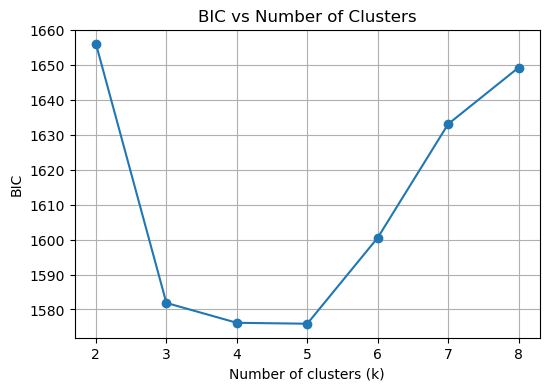

In [100]:
# BIC plot 
plt.figure(figsize=(6,4))
plt.plot(list(k_range), bic_values, marker='o')
plt.xticks(list(k_range))
plt.xlabel("Number of clusters (k)")
plt.ylabel("BIC")
plt.title("BIC vs Number of Clusters")
plt.grid(True)
plt.show()

In [101]:
# Final model is this:
weights, means, covs, resp, ll = gmm_train(X_scaled, best_k, seed=best_seed)

# interpretable cluster centers: we can convert means back to original scale:
means_original = means * stds_X + means_X

# Optionally, we can also assign each sample to a hard cluster:
cluster_labels = resp.argmax(axis=1)

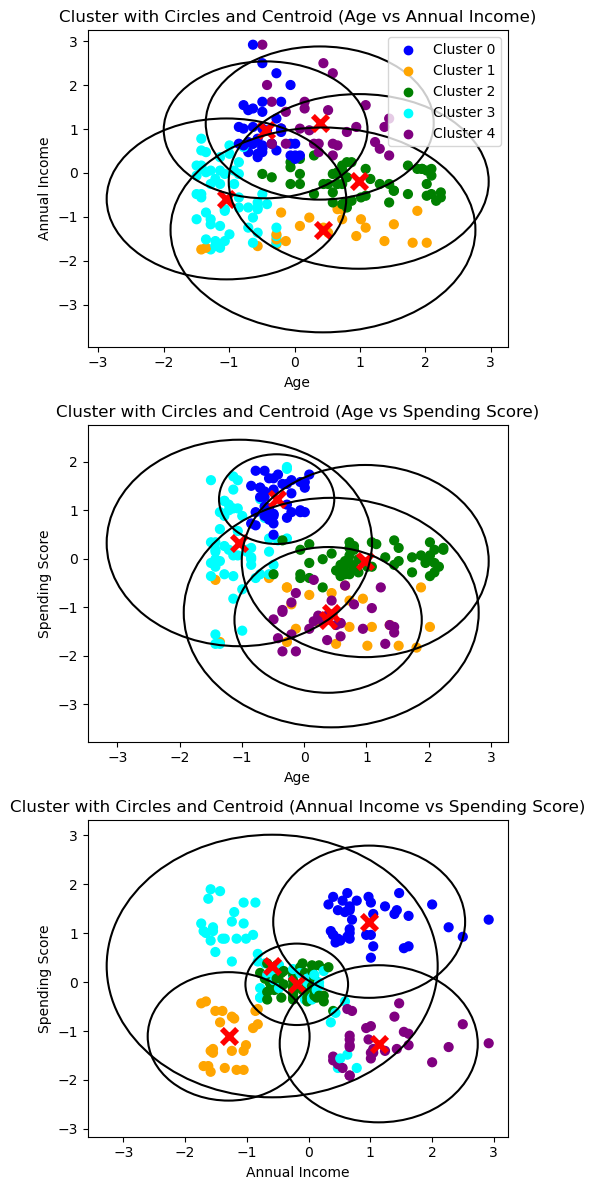

In [102]:
# 2D plot with cluster circles and centroid
feature_names = ['Age', 'Annual Income', 'Spending Score']

fig, axes = plt.subplots(3, 1, figsize=(5, 12))

pairs = [(0, 1), (0, 2), (1, 2)]

colors = ['blue', 'orange', 'green', 'cyan', 'purple', 'red']
cluster_colors = [colors[label] for label in cluster_labels]

for ax, (i, j) in zip(axes, pairs):
    ax.scatter(X_scaled[:, i], X_scaled[:, j], c=cluster_colors, s=40) # Scatter points
    ax.scatter(means[:, i], means[:, j], c='red', s=120, marker='x', linewidths=4) # Centroids

    # Covariance circles
    for k in range(best_k):
        cov_2d = covs[k][[i, j]][:, [i, j]]
        vals, vecs = np.linalg.eigh(cov_2d)
        radius = 2.5 * np.sqrt(vals.max())
        circle = Circle((means[k, i], means[k, j]), radius, fill=False,color='black', linewidth=1.5)
        ax.add_patch(circle)

    title = 'Cluster with Circles and Centroid (' + feature_names[i] + ' vs ' + feature_names[j] + ')'
    ax.set_title(title)
    ax.set_xlabel(feature_names[i])
    ax.set_ylabel(feature_names[j])

for i in range(best_k):
    axes[0].scatter([], [], color=colors[i], label=f"Cluster {i}")
axes[0].legend()
plt.tight_layout()
plt.show()

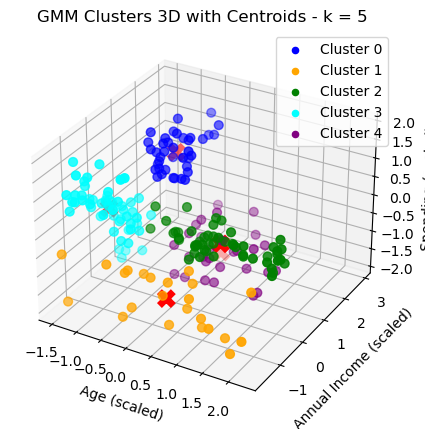

In [103]:
# 3D plot with cluster centroids
fig = plt.figure(figsize=(6,5))
ax = fig.add_subplot(111, projection='3d')

colors = ['blue', 'orange', 'green', 'cyan', 'purple', 'red']
cluster_colors = [colors[label] for label in cluster_labels]

ax.scatter(X_scaled[:,0], X_scaled[:,1], X_scaled[:,2],c=cluster_colors, s=40)

ax.scatter(means[:,0], means[:,1], means[:,2], c='red', s=100, marker='x', linewidths=5) # centroids

legend_handles = []
for i in range(best_k):
    h = ax.scatter([], [], [], color=colors[i], label=f"Cluster {i}")
    legend_handles.append(h)
    
ax.legend(handles=legend_handles, loc='upper right')

ax.set_xlabel("Age (scaled)")
ax.set_ylabel("Annual Income (scaled)")
ax.set_zlabel("Spending (scaled)")
plt.title("GMM Clusters 3D with Centroids - k = {}".format(best_k))
axes[0].legend()
plt.show()

In [104]:
# save segmented result 
df['Cluster'] = cluster_labels # Add to original dataframe

output_path = "segmented_customers.csv"
df.to_csv(output_path, index=False)

print("Saved to:", output_path)

Saved to: segmented_customers.csv


In [105]:
# first 10 rows: 
df.head(10)
# Or we can read eactly from saved file:
# pd.read_csv(output_path).head(10)

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,1
1,2,Male,21,15,81,3
2,3,Female,20,16,6,1
3,4,Female,23,16,77,3
4,5,Female,31,17,40,1
5,6,Female,22,17,76,3
6,7,Female,35,18,6,1
7,8,Female,23,18,94,3
8,9,Male,64,19,3,1
9,10,Female,30,19,72,3
